# BÀI TẬP VỀ NHÀ: PROBLEM SET 04 (JUPYTER NOTEBOOK)
## Môn học: Xác suất Thống kê (UET.MAT1052)
### Chủ đề: Mô hình tuyến tính & Hồi quy tuyến tính (Linear Regression)

---
**Họ và tên sinh viên:** Nguyễn Minh Đức  
**Mã số sinh viên (MSV):** 25021352  
**Lớp học phần:** 2627I_UET.MAT1052_51  

> **Hướng dẫn:** Hoàn thành các phần code và trả lời trực tiếp vào các ô markdown dưới đây. Chạy kiểm tra toàn bộ notebook trước khi nộp bài.

### Khởi động môi trường thư viện

In [1]:
import numpy as np
import pandas as pd
from plotnine import *


---
### BÀI 1: TƯƠNG QUAN PEARSON & ĐỘ NHẠY TRƯỚC NGOẠI LAI
Nhập dữ liệu 5 ứng viên ($ = kinh nghiệm, $ = lương):

In [2]:
# Dữ liệu 5 ứng viên
x = np.array([1, 2, 3, 4, 5])
y = np.array([10, 13, 15, 18, 24])

# TODO: Tính mean, std và hệ số tương quan r thủ công
mean_x = np.mean(x)
mean_y = np.mean(y)
std_x = np.std(x, ddof=1)
std_y = np.std(y, ddof=1)
r = np.corrcoef(x, y)[0, 1]

print(f"x: mean = {mean_x}, std = {std_x:.4f}")
print(f"y: mean = {mean_y}, std = {std_y:.4f}")
print(f"Hệ số tương quan r = {r:.4f}")

x: mean = 3.0, std = 1.5811
y: mean = 16.0, std = 5.3385
Hệ số tương quan r = 0.9774


In [4]:
# Thử nghiệm thêm điểm ngoại lai đòn bẩy cao: (x6 = 20, y6 = 22)
x_new = np.append(x, 20)
y_new = np.append(y, 22)
r_new = np.corrcoef(x_new, y_new)[0, 1]

print(f"Hệ số tương quan sau khi thêm điểm ngoại lai: r_new = {r_new:.4f}")

Hệ số tương quan sau khi thêm điểm ngoại lai: r_new = 0.6209


**Nhận xét Bài 1:**  
*Điền nhận xét của sinh viên tại đây Hệ số tương quan Pearson cực kỳ nhạy cảm với điểm ngoại lai có lực đòn bẩy cao. Ban đầu, dữ liệu gốc có mối tương quan thuận rất mạnh với \(r = 0.9774\). Tuy nhiên, chỉ cần thêm một điểm ngoại lai duy nhất là \((20, 22)\), hệ số tương quan đã lập tức sụt giảm nghiêm trọng xuống còn \(r_{new} = 0.6209\). Điểm này có giá trị lớn bất thường và không tuân theo xu hướng tăng tiến của tập dữ liệu cũ, làm bóp méo hoàn toàn kết quả đánh giá tuyến tính tổng thể. Thử nghiệm này chứng minh tầm quan trọng của việc vẽ biểu đồ phân tán để kiểm tra dữ liệu trước khi tính toán các chỉ số thống kê.*

---
### BÀI 2 & BÀI 3: MÔ HÌNH HỒI QUY ĐƠN BIẾN TRÊN DỮ LIỆU NGHÈO ĐÓI (51 BANG)
Sử dụng file 

In [7]:
df_poverty = pd.read_csv(r"D:\xacsuatthongke\Tuan 4\poverty_grad.csv")

# TODO: Khớp mô hình OLS với statsmodels
import statsmodels.formula.api as smf
model_pov = smf.ols("poverty ~ graduates", data=df_poverty).fit()

print(model_pov.summary())

                            OLS Regression Results                            
Dep. Variable:                poverty   R-squared:                       0.557
Model:                            OLS   Adj. R-squared:                  0.548
Method:                 Least Squares   F-statistic:                     61.64
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           3.23e-10
Time:                        09:27:15   Log-Likelihood:                -109.23
No. Observations:                  51   AIC:                             222.5
Df Residuals:                      49   BIC:                             226.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     64.6684      6.797      9.514      0.0

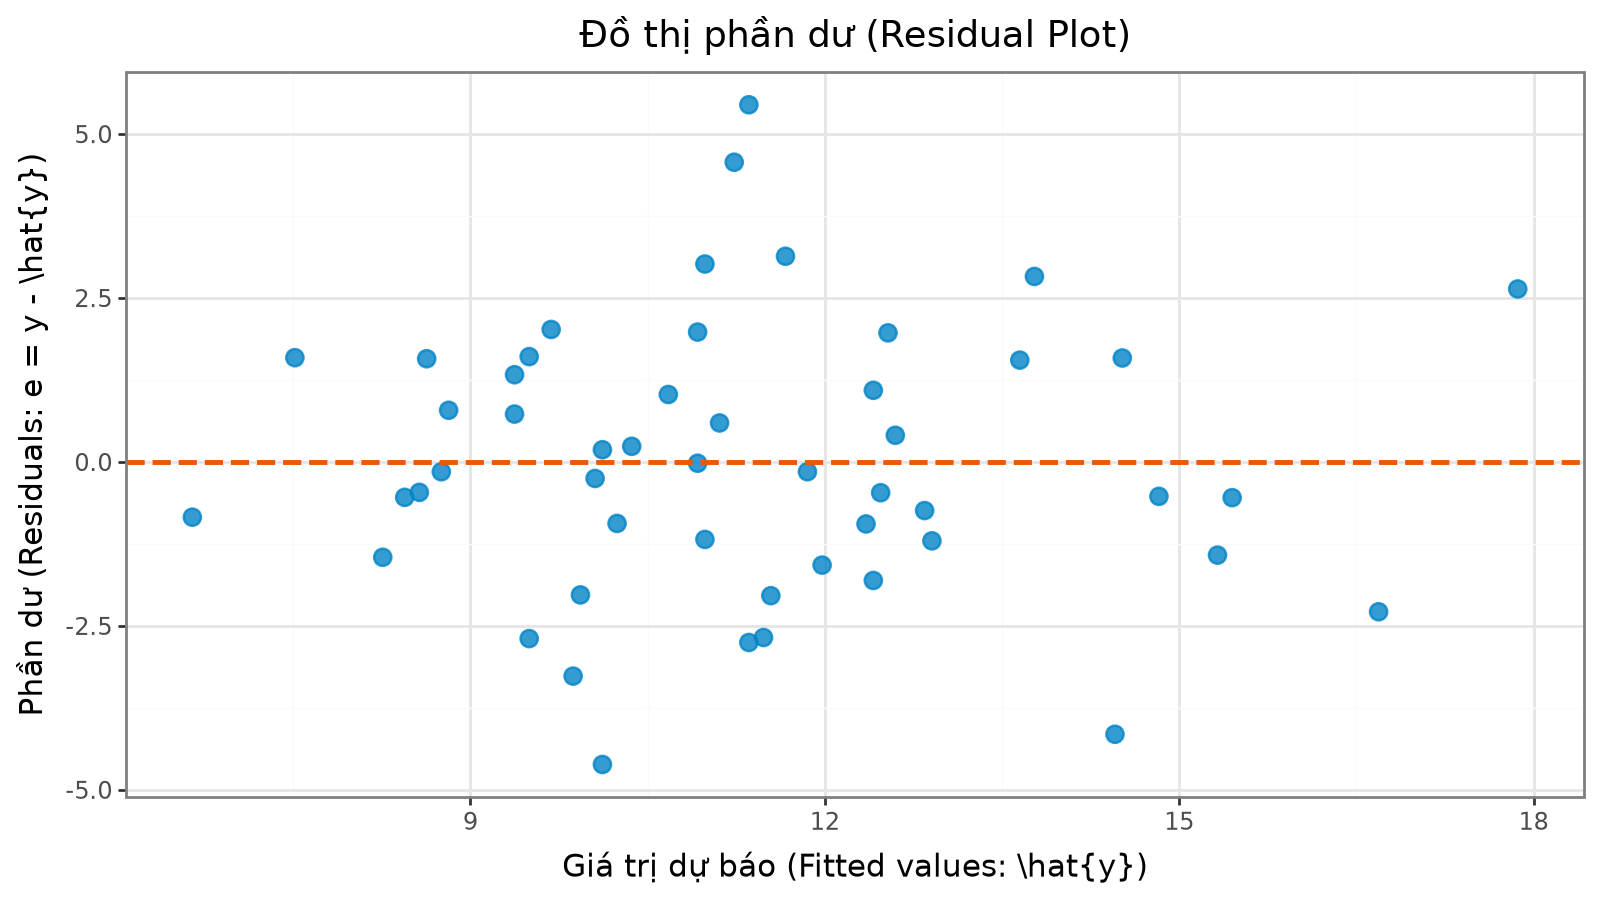

In [8]:
# Tính phần dư và vẽ Residual Plot bằng plotnine
df_poverty["fitted"] = model_pov.fittedvalues
df_poverty["resid"] = model_pov.resid

p_resid = (
    ggplot(df_poverty, aes(x="fitted", y="resid"))
    + geom_point(color="#0284c7", size=3, alpha=0.8)
    + geom_hline(yintercept=0, color="#ea580c", linetype="dashed", size=1)
    + labs(
        title="Đồ thị phần dư (Residual Plot)",
        x="Giá trị dự báo (Fitted values: \\hat{y})",
        y="Phần dư (Residuals: e = y - \\hat{y})"
    )
    + theme_bw()
    + theme(figure_size=(8, 4.5))
)
p_resid


**Nhận xét Bài 3:**  
*Phần dư của Utah và Washington D.C.; diễn giải ý nghĩa của ^2$...*

---
### BÀI 4: HỒI QUY ĐA BIẾN SONG SONG TRÊN DỮ LIỆU SÁCH ()
Dự báo khối lượng sách () theo thể tích () và loại bìa ().

In [10]:
df_books = pd.read_csv(r"D:\xacsuatthongke\Tuan 4\books.csv")

# TODO: Khớp mô hình song song weight ~ volume + C(cover)
model_books = smf.ols("weight ~ volume + C(cover)", data=df_books).fit()
print(model_books.summary())

                            OLS Regression Results                            
Dep. Variable:                 weight   R-squared:                       0.927
Model:                            OLS   Adj. R-squared:                  0.915
Method:                 Least Squares   F-statistic:                     76.73
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.45e-07
Time:                        09:33:21   Log-Likelihood:                -84.999
No. Observations:                  15   AIC:                             176.0
Df Residuals:                      12   BIC:                             178.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept               197.96

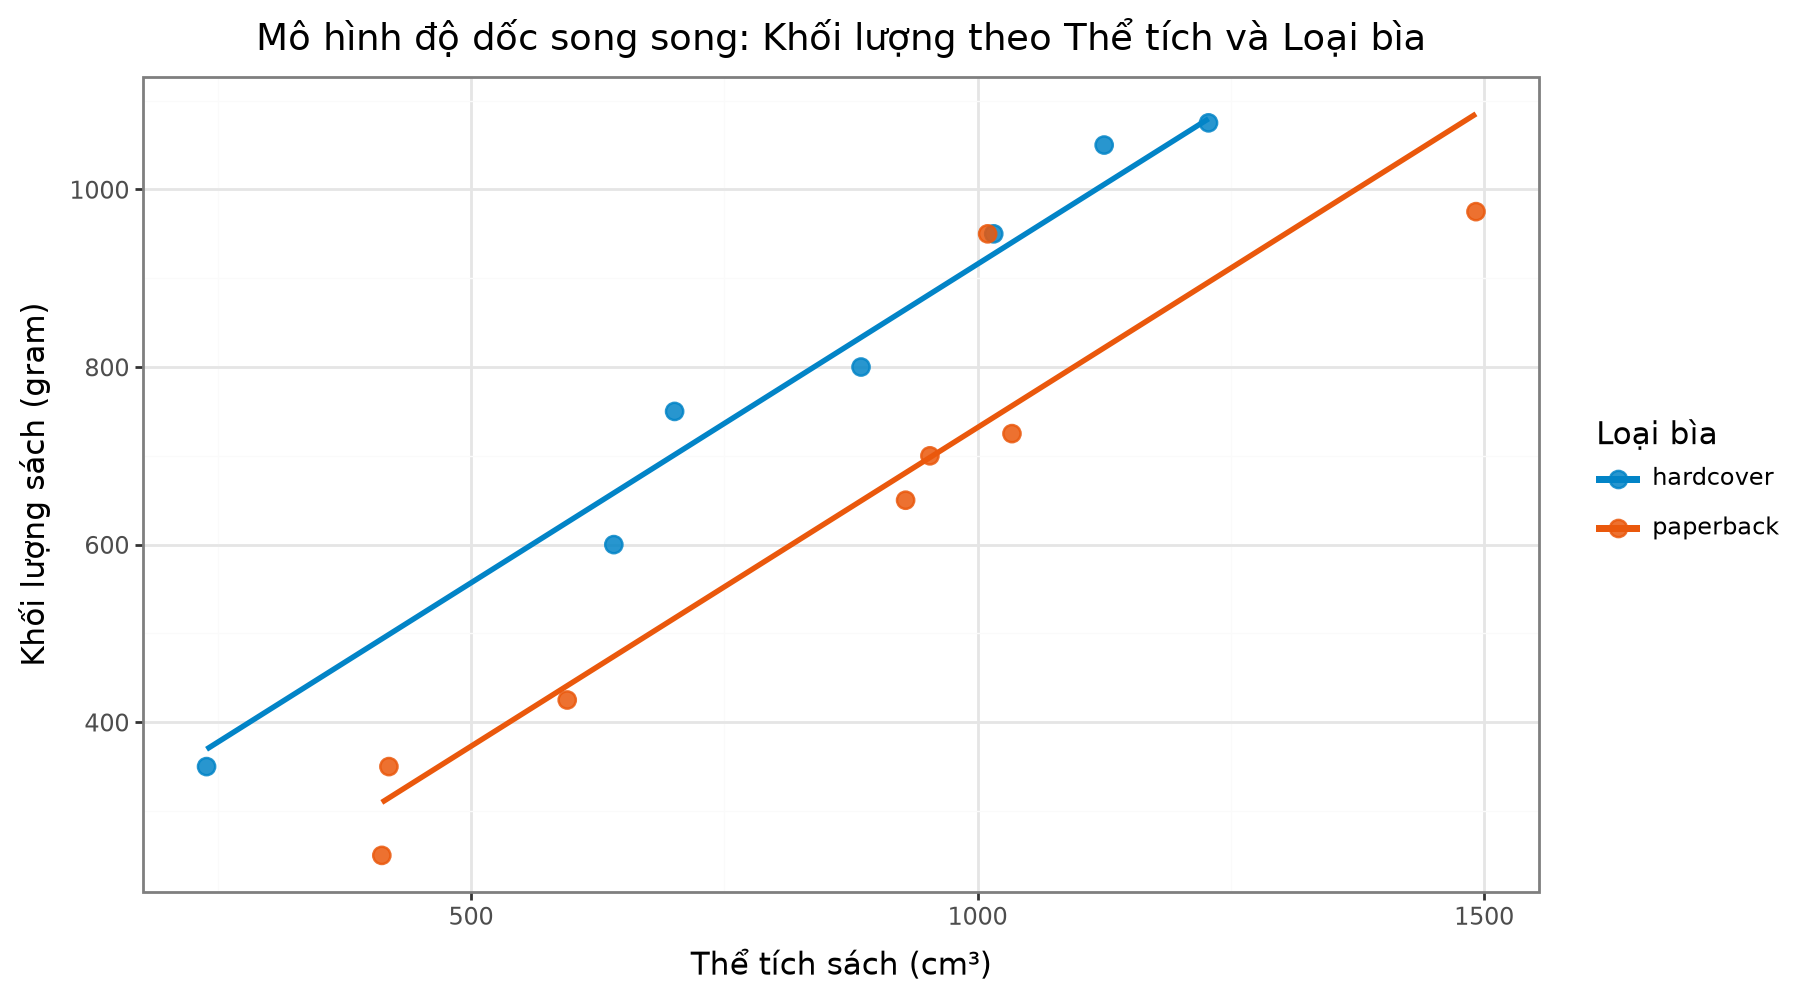

In [11]:
# Trực quan hóa hai đường thẳng song song bằng plotnine
df_books["fitted_weight"] = model_books.fittedvalues

p_books = (
    ggplot(df_books, aes(x="volume", y="weight", color="cover"))
    + geom_point(size=3, alpha=0.85)
    + geom_line(aes(y="fitted_weight", group="cover"), size=1.1)
    + scale_color_manual(values={"hardcover": "#0284c7", "paperback": "#ea580c"})
    + labs(
        title="Mô hình độ dốc song song: Khối lượng theo Thể tích và Loại bìa",
        x="Thể tích sách (cm³)",
        y="Khối lượng sách (gram)",
        color="Loại bìa"
    )
    + theme_bw()
    + theme(figure_size=(9, 5))
)
p_books


**Nhận xét Bài 4 & Bài 5:**  
*Diễn giải Ceteris Paribus và phân tích nguyên nhân tạo nên Nghịch lý Simpson trong hồi quy...*
*Diễn giải điều kiện Ceteris Paribus: Trong mô hình hồi quy đa biến song song, hệ số hồi quy của biến volume là 0.7180, mang ý nghĩa rằng trong điều kiện các yếu tố khác không đổi (Ceteris Paribus - tức là khi giữ nguyên cùng một loại bìa sách là bìa cứng hardcover hoặc bìa mềm paperback), nếu thể tích sách tăng thêm \(1\text{ cm}^3\) thì khối lượng sách được dự báo sẽ tăng trung bình 0.7180 gram. Ngược lại, hệ số của biến giả C(cover)[T.paperback] là -184.0473 cho biết trong điều kiện giữ nguyên cùng một mức thể tích sách, một cuốn sách có bìa mềm (paperback) sẽ có khối lượng nhẹ hơn trung bình 184.0473 gram so với một cuốn sách có bìa cứng (hardcover).*


*Phân tích nguyên nhân tạo nên hiện tượng (nghịch lý Simpson): Hiện tượng bóp méo hoặc đảo ngược mối quan hệ giữa thể tích và khối lượng nếu vô tình bỏ qua biến phân loại Loại bìa xuất phát từ sự xuất hiện của một biến ẩn/biến nhiễu (confounding variable). Trên biểu đồ phân tán, dữ liệu thực tế bị chia tách rõ rệt thành hai phân nhóm có hành vi khác nhau. Nếu phân tích gộp chung tất cả các quan sát mà không phân biệt loại bìa, đường xu hướng tổng thể có thể bị kéo lệch, làm sai lệch độ dốc thực tế (hệ số góc) hoặc làm giảm độ chính xác của dự báo do các điểm dữ liệu bìa mềm phân bố dịch hẳn xuống phía dưới và sang bên phải. Việc đưa biến định tính C(cover) vào mô hình giúp bóc tách và kiểm soát tác động riêng biệt của từng nhóm, loại bỏ sự nhiễu loạn thông tin, từ đó phản ánh chính xác mối quan hệ tuyến tính đồng nhất giữa thể tích và khối lượng của sách qua hai đường thẳng song song mang bản chất thực sự của dữ liệu.*